# inclined: inclined test particles (epi_int_3d)

tests/unperturbed's 51 eccentric streamlines (3 particles each, 10⁻⁸ < e < 10⁻²), without ring forces,
each particle given inclination i = 0.01, run for 1000 orbits with `fast/epi_int_3d.py`.
Expectations (notes/equations.md V1–V4, V8):

1. every particle keeps its inclination;
2. its node regresses at Ω_a − ν_a, about 270 orbits per cycle here;
3. integrated exactly in the 3D J2 potential, the same particles regress at a rate within O(i², e²) of that.

Make the output with `uv run python tools/run_simulations.py tests/inclined` (about 2 s).

In [1]:
import sys
sys.path.insert(0, '../../source')
sys.path.insert(0, '../../fast')
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
from vertical_analysis import load3d, inclined_metrics, exact_orbits, nodal_rate
plt.rcParams.update({'font.size': 13})
p, o = load3d('.')
orbits = (o['times'] - o['times'][0])/(2*np.pi)
for k in ('number_of_streamlines', 'particles_per_streamline', 'dt', 'J2', 'Rp', 'total_ring_mass', 'inclination', 'node'):
    print(k, '=', p[k])

number_of_streamlines = 51
particles_per_streamline = 3
dt = 0.5
J2 = 0.01
Rp = 0.5
total_ring_mass = 0.0
inclination = 0.01
node = 0.0


## 1, 2: inclination and node versus the drift's own equations

max_delta_inc_rel = 1.83e-13
max_delta_node = 2.62e-11
max_delta_a = 5.55e-13
regression_orbits = 268


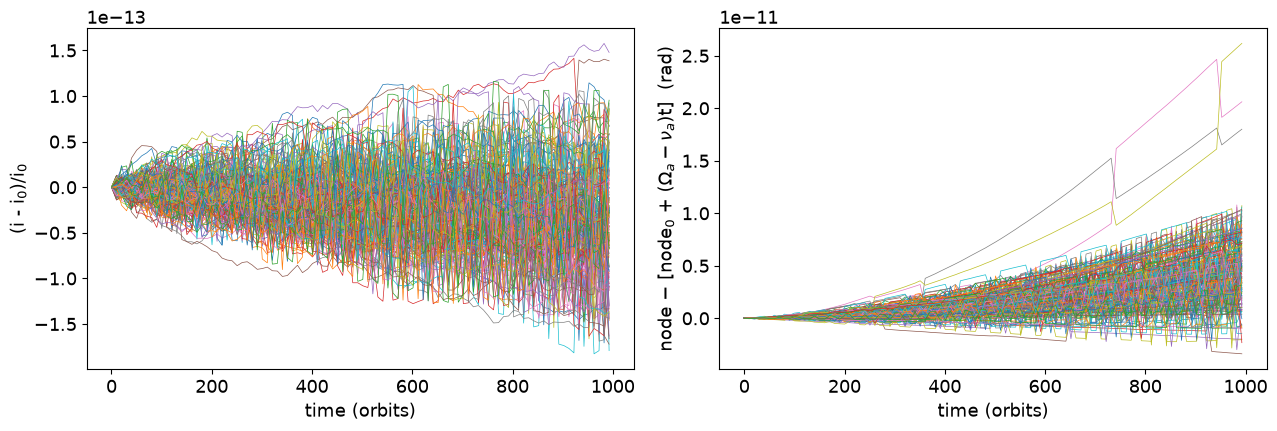

In [2]:
m = inclined_metrics(p, o)
for k, v in m.items():
    print(f'{k} = {v:.3g}')
rate = nodal_rate(p, o['a'][0])
dnode = o['node'] - (o['node'][0] + rate*(o['times'] - o['times'][0])[:, None, None])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(orbits, ((o['inc'] - o['inc'][0])/o['inc'][0]).reshape(len(orbits), -1), lw=0.5)
ax[0].set_xlabel('time (orbits)'); ax[0].set_ylabel('(i - i$_0$)/i$_0$')
ax[1].plot(orbits, dnode.reshape(len(orbits), -1), lw=0.5)
ax[1].set_xlabel('time (orbits)'); ax[1].set_ylabel(r'node $-$ [node$_0$ + ($\Omega_a - \nu_a$)t]  (rad)')
plt.tight_layout()

Both are at roundoff: the drift applies V8, which is V2–V4 exactly, and without ring forces nothing
else changes i or a. (The node residual grows with time because a wanders at the 10⁻¹³ level from roundoff,
which shifts the regression rate, ∝ a^(−7/2).) The node goes through 3.7 cycles:

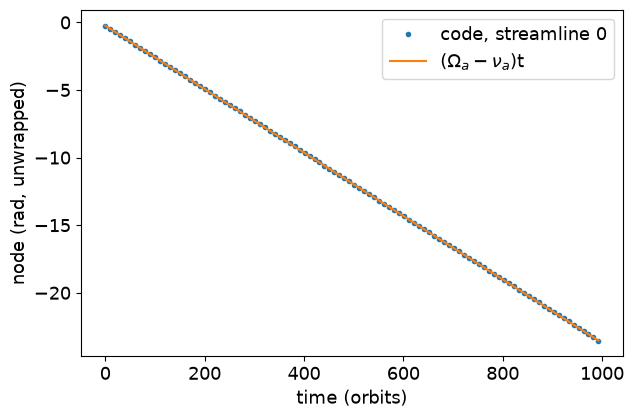

In [3]:
j = 0
plt.figure(figsize=(7, 4.5))
plt.plot(orbits, o['node'][:, j, 0], 'o', ms=3, label='code, streamline 0')
plt.plot(orbits, o['node'][0, j, 0] + rate[j, 0]*(o['times'] - o['times'][0]), label=r'($\Omega_a - \nu_a$)t')
plt.xlabel('time (orbits)'); plt.ylabel('node (rad, unwrapped)'); plt.legend()

## 3: versus exact integration in the 3D J2 potential

Particle 0 of every streamline, integrated with DOP853 from its state at the first output; its node is
measured with the same epicyclic elements (V3) as the code's, which removes most short-period terms.

e < 1e-4: (exact rate)/(code rate) - 1 = -4.0411e-04, std 1.8e-06;  -4 i^2 = -4.0e-04
e > 1e-3: [(exact)/(code) - 1 + 4 i^2]/e^2 = -4.31


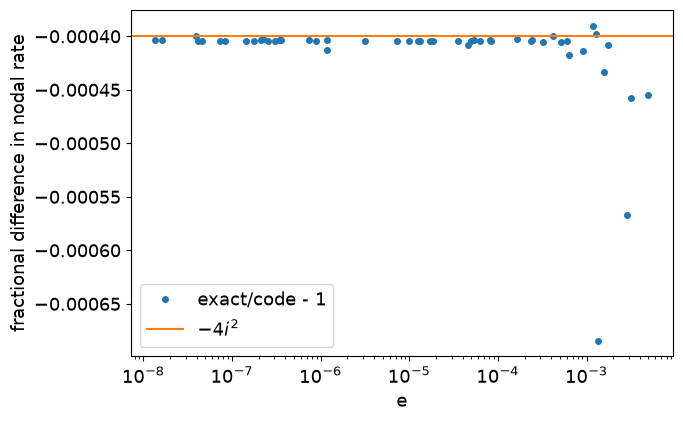

In [4]:
Nr = o['r'].shape[1]
idx = (np.arange(Nr), np.zeros(Nr, int))
node_exact, node_code = exact_orbits(p, o, idx)
T = o['times'] - o['times'][0]
d = np.polyfit(T, node_exact, 1)[0]/np.polyfit(T, node_code, 1)[0] - 1
e = o['e'][0][idx]
i = p['inclination']
print(f'e < 1e-4: (exact rate)/(code rate) - 1 = {np.median(d[e < 1e-4]):.4e}, std {d[e < 1e-4].std():.1e};  -4 i^2 = {-4*i*i:.1e}')
print(f'e > 1e-3: [(exact)/(code) - 1 + 4 i^2]/e^2 = {np.median(((d + 4*i*i)/e**2)[e > 1e-3]):.2f}')
plt.figure(figsize=(7, 4.5))
plt.semilogx(e, d, 'o', ms=4, label='exact/code - 1')
plt.axhline(-4*i*i, color='C1', label=r'$-4i^2$')
plt.xlabel('e'); plt.ylabel('fractional difference in nodal rate'); plt.legend()

The code's nodes regress faster than the exact ones by 4i², the first-order theory's O(i²) error. Its
origin is simple: the code's semimajor axis comes from h_z = r v_θ = h cos i, so a_code = a cos²i, and the
nodal rate ∝ a^(−7/2) cos i, so exact/code = cos⁸i ≈ 1 − 4i². Runs at i = 0.003 and 0.001 give the
same −4.04 i², with scatter 2×10⁻⁶ and 6×10⁻⁷ for e < 10⁻⁴.

For e ≳ 10⁻³ the difference grows roughly as e² (coefficient −3 to −4), with a few outliers. Those come from
the measurement: the exact orbits' nodes (V3) carry short-period terms of amplitude ≈ 2e rad (the theory's
O(e·i) error in z, V6), which the 10-orbit spacing of the outputs aliases into slow wobbles that bias the
fitted rates.